Project root: c:\Users\sinco\Documents\GitHub\Medical-Imaging-Research
Dataset found: True
Image root found: True
Total MRI images: 11520

Class distribution:
label
1    10323
0     1197
Name: count, dtype: int64

MRI sequences:
sequence
T1C+    4642
T1      3799
T2      3079
Name: count, dtype: int64

Saved manifest: c:\Users\sinco\Documents\GitHub\Medical-Imaging-Research\Code\preprocessing\manifests\brain_mri_master_manifest.csv


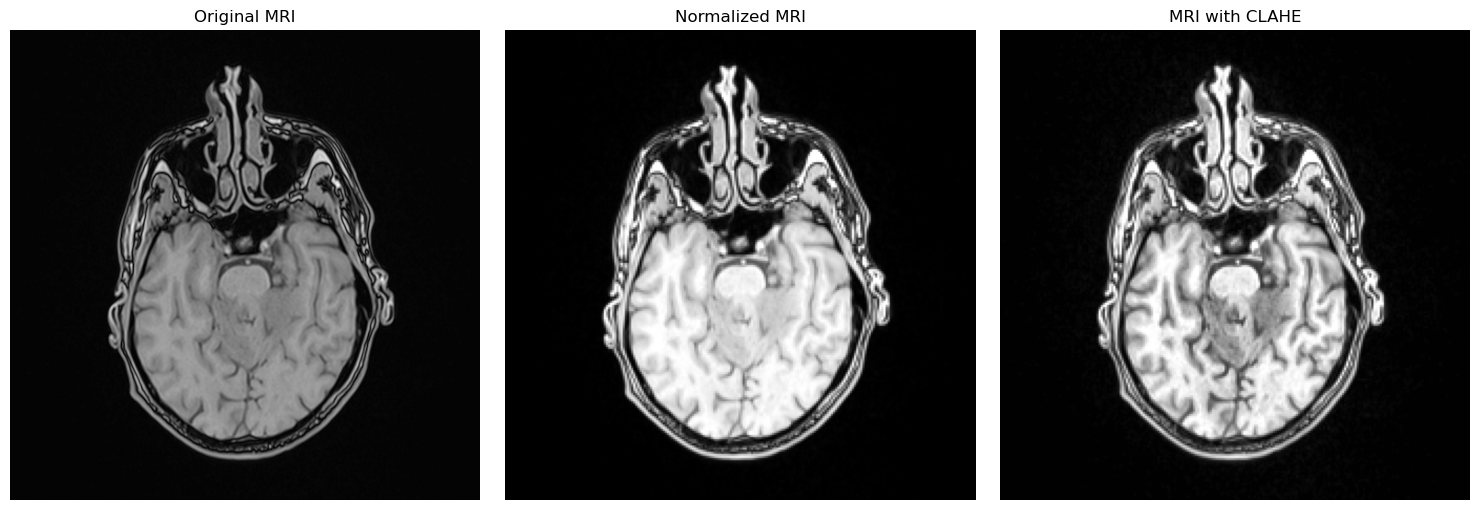

Original shape: (512, 512)
Preprocessed shape: (224, 224)
Intensity range: 0.0 1.0


In [20]:
%run C:\Users\sinco\Documents\GitHub\Medical-Imaging-Research\Code\models\preprocessing\01_mri_preprocessing.ipynb



In [21]:
import pandas as pd
import polars as pl
from sklearn import svm

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report

X = np.stack([
    preprocess_mri(path, image_size=(64, 64)).ravel()
    for path in df["image_path"]
])
y = df["label"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

svm = make_pipeline(
    StandardScaler(),
    LinearSVC(random_state=SEED, max_iter=5000)
)
svm.fit(X_train, y_train)

print(classification_report(y_test, svm.predict(X_test)))

              precision    recall  f1-score   support

           0       0.74      0.72      0.73       239
           1       0.97      0.97      0.97      2065

    accuracy                           0.94      2304
   macro avg       0.85      0.85      0.85      2304
weighted avg       0.94      0.94      0.94      2304



c:\Users\sinco\anaconda3\Lib\site-packages\sklearn\svm\_base.py:1250: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


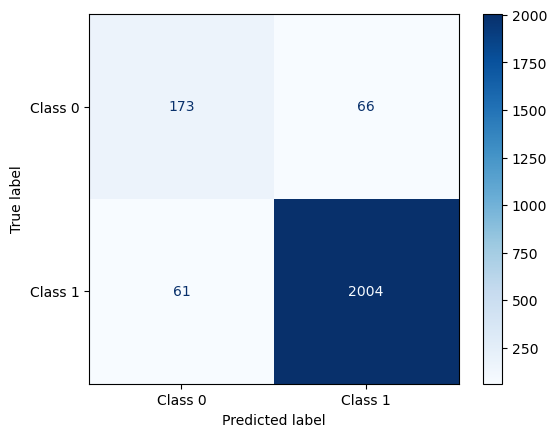

In [35]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, svm.predict(X_test))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Class 0", "Class 1"])
disp.plot(cmap=plt.cm.Blues)
plt.show()